# 02. CO₂ 10분 뒤 예측 — 선형회귀(손계산) vs 인공신경망
**목표:** 지금까지의 CO₂ 흐름과 창문 상태로 **10분 뒤 CO₂**를 예측해, 졸음 임계값을 넘기 *전에* 환기를 알린다.

사람이 라벨을 달 필요가 없는 문제라(정답 = 10분 뒤 실제 측정값) 측정한 기록 전부를 학습에 쓸 수 있다.

**데이터**
- 교실: 데이터과학 수행 때 7반 교실에서 1분마다 잰 CO₂·온습도·창문 8개 열림 정도 (`datasci_*.csv`)
- 집: 이번 장치(ESP32)로 잰 10초 기록을 1분 평균으로 만든 것 (`co2_1min.csv`)

**비교할 예측 방법**
1. 그대로 유지: 10분 뒤에도 지금 값 (가장 단순한 기준선)
2. 직선 연장: 최근 10분 기울기를 그대로 이어감 (지금 펌웨어의 '임계값 도달 예상 시간' 방식)
3. 선형회귀: 경사하강법을 손으로 유도해 학습 (손실함수 · 편미분 · 헤시안 · 고윳값 · 학습률 범위)
4. k-NN 회귀, 랜덤 포레스트 회귀 (머신러닝 비교 모델)
5. **인공신경망(MLP)**: 은닉층 2개(16, 8), ReLU

In [1]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from common import *

H = 10                       # 예측 거리(분)
LAGS = [1, 2, 5, 10]          # 과거 변화량을 볼 시점(분 전)

def load_classroom():
    fs = sorted(glob.glob(f"{RAW}/datasci_7ban_*.csv"))
    out = []
    for f in fs:
        d = pd.read_csv(f, encoding="utf-8-sig")
        tcol = "measured_at" if "measured_at" in d else d.columns[0]
        d["time"] = pd.to_datetime(d[tcol])
        wc = [c for c in d.columns if c.lower().startswith("w") and c[1:].isdigit()]
        d["win"] = d[wc].fillna(0).mean(axis=1) if wc else 0.0
        d = d.rename(columns={"temp_c": "temp", "humidity": "hum"})
        out.append(d[["time", "co2", "temp", "win"]])
    if not out: return None
    d = pd.concat(out).drop_duplicates("time").sort_values("time")
    d = d.set_index("time").resample("1min").mean()      # 1분 격자로 맞춤(빠진 분은 NaN)
    # 센서가 순간적으로 400ppm 근처로 튀는 측정 오류(1~2분) 제거: 주변 7분 중앙값과 300ppm 넘게 다르면 결측
    med = d["co2"].rolling(7, center=True, min_periods=3).median()
    bad = (d["co2"] - med).abs() > 300
    print(f"교실 데이터 순간 튐 제거: {int(bad.sum())}분")
    d.loc[bad, "co2"] = np.nan
    d["src"] = "교실"; return d.reset_index()

def load_home():
    try: d = pd.read_csv(f"{PROC}/co2_1min.csv", encoding="utf-8-sig")
    except FileNotFoundError: return None
    d["time"] = pd.to_datetime(d["time"]).dt.tz_localize(None) if pd.to_datetime(d["time"]).dt.tz is None else pd.to_datetime(d["time"]).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)
    d = d.groupby("time", as_index=False).mean(numeric_only=True)
    d = d.set_index("time").resample("1min").mean()
    d["temp"] = np.nan; d["win"] = 0.0; d["src"] = "집"
    return d.reset_index()[["time", "co2", "temp", "win", "src"]]

def make_xy(d):
    """1분 격자 → (특징, 정답). 과거·미래 값이 하나라도 비면 그 시점은 버림.
    센서 잡음(±수십 ppm)을 줄이려고 '직전 3분 중앙값'으로 다듬은 값을 쓴다(미래 값은 쓰지 않음)."""
    c = d["co2"].rolling(3, min_periods=2).median()
    X = pd.DataFrame({"co2": c})
    for k in LAGS: X[f"d{k}"] = c - c.shift(k)           # k분 동안의 변화량
    X["win"] = d["win"].fillna(0); X["dwin"] = X["win"] - X["win"].shift(5).fillna(0)
    y = c.shift(-H) - c                                     # 10분 뒤 변화량을 예측
    ok = X.notna().all(axis=1) & y.notna()
    return X[ok], y[ok], d.loc[ok, "time"], d.loc[ok, "src"]

parts = [p for p in (load_classroom(), load_home()) if p is not None]
for p in parts: print(f"{p.src.iloc[0]}: {p.time.min():%m-%d %H:%M} ~ {p.time.max():%m-%d %H:%M}, CO₂ 측정 {p.co2.notna().sum():,}분")
XY = [make_xy(p) for p in parts]
X = pd.concat([a[0] for a in XY]); y = pd.concat([a[1] for a in XY])
T = pd.concat([a[2] for a in XY]); S = pd.concat([a[3] for a in XY])
print(f"학습 가능한 시점: {len(X):,}개")

교실 데이터 순간 튐 제거: 25분
교실: 11-02 14:06 ~ 11-06 17:52, CO₂ 측정 4,270분
집: 11-14 13:20 ~ 11-15 13:18, CO₂ 측정 1,430분
학습 가능한 시점: 5,551개


## 평가 방법 — 하루씩 빼서 시험(교차검증)
무작위로 섞으면 1분 차이 나는 거의 같은 시점이 학습과 평가에 동시에 들어가 성능이 부풀려진다(데이터 누수). 그래서 **하루를 통째로 빼서 평가하고 나머지 날로 학습**하는 것을 날마다 반복해 평균을 낸다. 학습한 적 없는 새로운 날을 얼마나 잘 맞히는지를 보는 방법이다.

입력 특징: 1·2·5·10분 동안의 CO₂ 변화량, 창문 열림 정도와 그 변화 (CO₂ 절댓값은 날마다 수준이 달라 일반화를 해쳐 뺐다)

In [2]:
FEATS = [f"d{k}" for k in LAGS] + ["win", "dwin"]
day = T.dt.date
days = [d for d in sorted(day.unique()) if (day == d).sum() >= 100]
print("평가에 쓰는 날:", [str(d) for d in days])

평가에 쓰는 날: ['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-14', '2026-11-15']


## 선형회귀를 경사하강법으로 — 손으로 유도하기
모델: $\hat y = \mathbf{x}^\top \mathbf{w} + b$ (특징은 z-점수로 표준화, $\hat y$ = 10분 뒤 CO₂ 변화량)

손실(평균제곱오차): $L(\mathbf w,b)=\frac1n\sum_{i=1}^n (y_i-\mathbf x_i^\top\mathbf w-b)^2$

편미분: $\frac{\partial L}{\partial \mathbf w}=-\frac2n X^\top(\mathbf y-X\mathbf w-b),\quad \frac{\partial L}{\partial b}=-\frac2n\sum(y_i-\hat y_i)$

헤시안(두 번 미분): 편향까지 포함한 $\tilde X=[X\;\mathbf 1]$에 대해 $H=\frac2n\tilde X^\top\tilde X$ — **w와 상관없이 일정**하고 모든 고윳값이 0 이상(양의 준정부호)이라 $L$은 볼록함수 → 극소점이 곧 최소점이다.

학습률 조건: 경사하강 $\mathbf w\leftarrow\mathbf w-\eta\nabla L$ 의 오차는 매 단계 $(I-\eta H)$가 곱해지므로, 모든 고윳값에 대해 $|1-\eta\lambda|<1$ 즉 $0<\eta<\dfrac{2}{\lambda_{\max}(H)}$ 여야 수렴한다.

헤시안 고윳값: [0.164 0.346 1.247 1.559 2.    2.468 6.215]
λmax = 6.215 → 학습률 상한 2/λmax = 0.322,  λmin = 0.1641 (>0 → 유일한 최소점)
조건수 λmax/λmin = 37.9 (변화량 특징끼리 상관이 높아 1보다 큼 → 경사하강이 느려짐)
경사하강 결과 w: [51.46  5.62 16.92 -0.41 -2.18  4.33 -1.77]
정규방정식 해  w: [51.46  5.62 16.92 -0.41 -2.18  4.33 -1.77] → 두 결과가 같으므로 유도한 기울기 식이 맞다


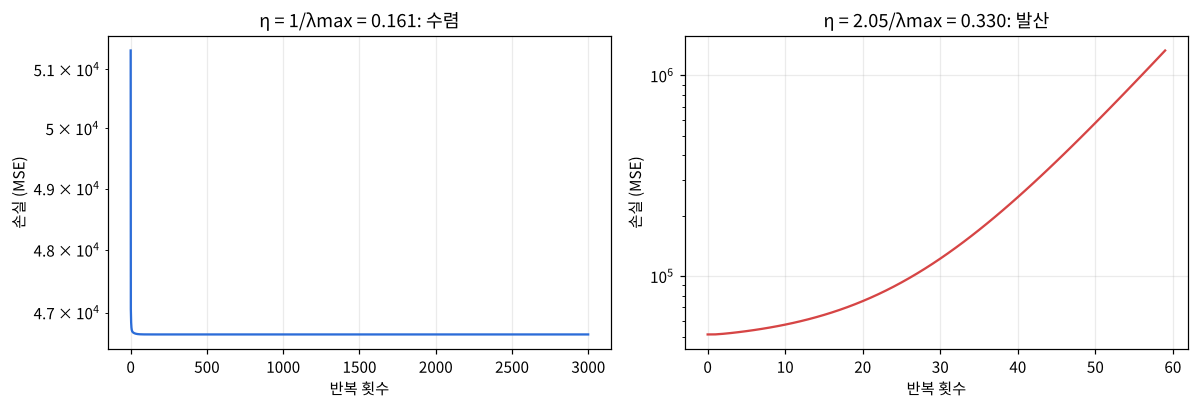

In [3]:
sc_all = StandardScaler().fit(X[FEATS])
Z = sc_all.transform(X[FEATS]); n = len(Z); Xt = np.hstack([Z, np.ones((n, 1))]); yy = y.to_numpy()
Hs = 2 / n * Xt.T @ Xt
lam = np.linalg.eigvalsh(Hs)
print("헤시안 고윳값:", np.round(lam, 3))
print(f"λmax = {lam.max():.3f} → 학습률 상한 2/λmax = {2/lam.max():.3f},  λmin = {lam.min():.4f} (>0 → 유일한 최소점)")
print(f"조건수 λmax/λmin = {lam.max()/lam.min():.1f} (변화량 특징끼리 상관이 높아 1보다 큼 → 경사하강이 느려짐)")

def gd(Xm, yv, eta, steps=3000):
    w = np.zeros(Xm.shape[1]); hist = []; m = len(yv)
    for _ in range(steps):
        r = yv - Xm @ w
        hist.append((r ** 2).mean())
        w -= eta * (-2 / m * Xm.T @ r)
    return w, hist

w_ok, h_ok = gd(Xt, yy, 1.0 / lam.max())
w_bad, h_bad = gd(Xt, yy, 2.05 / lam.max(), steps=60)
w_exact = np.linalg.lstsq(Xt, yy, rcond=None)[0]
print("경사하강 결과 w:", np.round(w_ok, 2))
print("정규방정식 해  w:", np.round(w_exact, 2), "→ 두 결과가 같으므로 유도한 기울기 식이 맞다")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(h_ok, color="#2b6cd8"); ax[0].set_yscale("log"); ax[0].set_title(f"η = 1/λmax = {1/lam.max():.3f}: 수렴")
ax[1].plot(h_bad, color="#d64545"); ax[1].set_yscale("log"); ax[1].set_title(f"η = 2.05/λmax = {2.05/lam.max():.3f}: 발산")
for a in ax: a.set_xlabel("반복 횟수"); a.set_ylabel("손실 (MSE)"); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/02_gd_learning_rate.png", dpi=150); plt.show()

## 여섯 가지 방법 비교 (하루씩 빼서 평가)

In [4]:
def mlp_model():
    return MLPRegressor(hidden_layer_sizes=(16, 8), activation="relu", alpha=1e-2, learning_rate_init=1e-3,
                        max_iter=1500, early_stopping=True, validation_fraction=.15, random_state=0)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
P = {k: pd.Series(np.nan, index=X.index) for k in ["그대로 유지", "직선 연장(현재 펌웨어)", "선형회귀(경사하강)", "k-NN 회귀 (k=25)", "랜덤 포레스트 회귀", "인공신경망(MLP)"]}
for d in days:
    te = (day == d); tr = ~te
    sc = StandardScaler().fit(X.loc[tr, FEATS]); a, b = sc.transform(X.loc[tr, FEATS]), sc.transform(X.loc[te, FEATS])
    lam_d = np.linalg.eigvalsh(2 / len(a) * np.hstack([a, np.ones((len(a), 1))]).T @ np.hstack([a, np.ones((len(a), 1))])).max()
    w, _ = gd(np.hstack([a, np.ones((len(a), 1))]), y[tr].to_numpy(), 1.0 / lam_d)
    P["그대로 유지"][te] = 0.0
    P["직선 연장(현재 펌웨어)"][te] = X.loc[te, "d10"]
    P["선형회귀(경사하강)"][te] = np.hstack([b, np.ones((len(b), 1))]) @ w
    P["k-NN 회귀 (k=25)"][te] = KNeighborsRegressor(25).fit(a, y[tr]).predict(b)
    P["랜덤 포레스트 회귀"][te] = RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=20, random_state=0, n_jobs=-1).fit(a, y[tr]).predict(b)
    P["인공신경망(MLP)"][te] = mlp_model().fit(a, y[tr]).predict(b)

ev = day.isin(days)
rising = ev & (X["d10"] > 20) & (X["co2"] > 1000)          # 사람이 있고 CO₂가 오르는 중(환기 알림이 필요한 상황)
rows = []
for k, p in P.items():
    e = (y - p).abs()
    rows.append({"방법": k, "전체 MAE(ppm)": e[ev].mean(), "전체 RMSE(ppm)": np.sqrt(((y - p)[ev] ** 2).mean()),
                 "CO₂ 상승 중 MAE(ppm)": e[rising].mean()})
res = pd.DataFrame(rows).round(1); print(res.to_string(index=False))
base = res.set_index("방법")
print(f"\nCO₂가 오르는 중일 때 MLP 오차는 '그대로 유지'보다 "
      f"{(1 - base.loc['인공신경망(MLP)','CO₂ 상승 중 MAE(ppm)']/base.loc['그대로 유지','CO₂ 상승 중 MAE(ppm)'])*100:.0f}%, "
      f"현재 펌웨어 방식보다 {(1 - base.loc['인공신경망(MLP)','CO₂ 상승 중 MAE(ppm)']/base.loc['직선 연장(현재 펌웨어)','CO₂ 상승 중 MAE(ppm)'])*100:.0f}% 작다")
res.to_csv(f"{RES}/02_forecast_scores.csv", index=False, encoding="utf-8-sig")

            방법  전체 MAE(ppm)  전체 RMSE(ppm)  CO₂ 상승 중 MAE(ppm)
        그대로 유지        113.0         226.6              242.5
 직선 연장(현재 펌웨어)        134.6         291.4              240.4
    선형회귀(경사하강)        108.0         218.7              224.2
k-NN 회귀 (k=25)        114.0         223.9              221.7
    랜덤 포레스트 회귀        107.4         218.0              218.0
    인공신경망(MLP)        107.1         220.3              213.9

CO₂가 오르는 중일 때 MLP 오차는 '그대로 유지'보다 12%, 현재 펌웨어 방식보다 11% 작다


## 예측 곡선 (교실, CO₂ 변화가 가장 컸던 날)

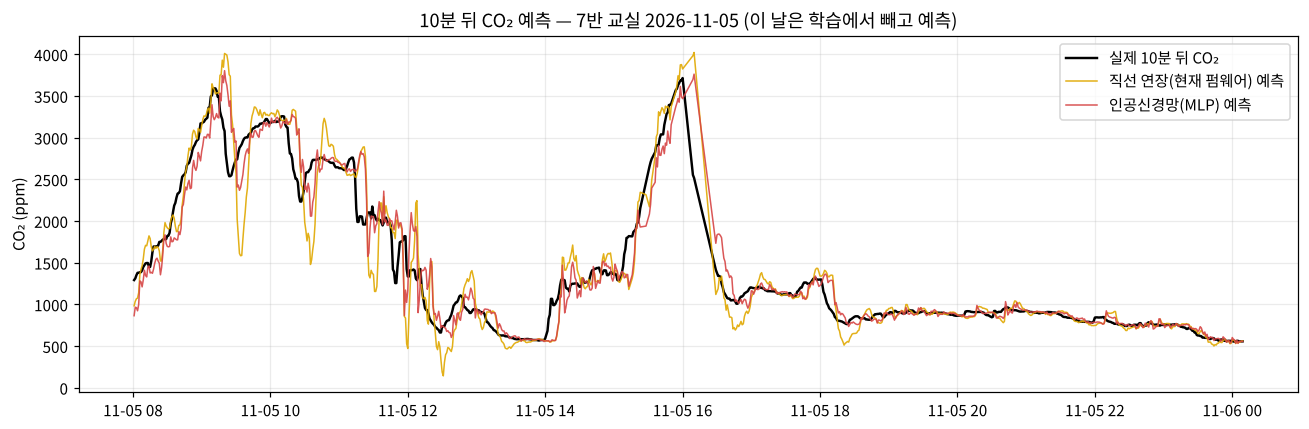

In [5]:
cls_days = [d for d in days if (S[day == d] == "교실").all()]
d = max(cls_days, key=lambda dd: X.loc[day == dd, "co2"].std()); m = (day == d)
now = X.loc[m, "co2"]; tt = T[m] + pd.Timedelta(minutes=H)
fig, a = plt.subplots(figsize=(12, 4))
a.plot(tt, now + y[m], color="black", lw=1.6, label="실제 10분 뒤 CO₂")
for k, c in [("직선 연장(현재 펌웨어)", "#e0a800"), ("인공신경망(MLP)", "#d64545")]:
    a.plot(tt, now + P[k][m], lw=1, color=c, label=k + " 예측", alpha=.9)
a.set_ylabel("CO₂ (ppm)"); a.set_title(f"10분 뒤 CO₂ 예측 — 7반 교실 {d} (이 날은 학습에서 빼고 예측)"); a.legend(); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/02_forecast_curve.png", dpi=150); plt.show()

## 환기 알림으로 써 보기
"지금은 임계값 아래인데 10분 안에 넘는다"를 미리 맞히는지 평가한다. 임계값은 교실에서 자주 나타난 2000ppm.
- 재현율: 실제로 넘은 경우 중 미리 알린 비율 (놓치지 않는 능력)
- 정밀도: 알린 경우 중 실제로 넘은 비율 (헛알림이 없는 능력)

In [6]:
TH = 2000
alert_rows = []
now_all = X["co2"]; actual = ev & (now_all < TH) & (now_all + y >= TH)
for k, p in P.items():
    warn = ev & (now_all < TH) & (now_all + p >= TH)
    tp = (warn & actual).sum(); fp = (warn & ~actual).sum(); fn = (~warn & actual).sum()
    alert_rows.append({"방법": k, "미리 맞힘": tp, "놓침": fn, "헛알림": fp,
                       "재현율": round(tp / max(tp + fn, 1), 2), "정밀도": round(tp / max(tp + fp, 1), 2)})
al = pd.DataFrame(alert_rows); print(al.to_string(index=False))
al.to_csv(f"{RES}/02_alert_scores.csv", index=False, encoding="utf-8-sig")

            방법  미리 맞힘  놓침  헛알림  재현율  정밀도
        그대로 유지      0 133    0 0.00 0.00
 직선 연장(현재 펌웨어)     56  77   35 0.42 0.62
    선형회귀(경사하강)     28 105    3 0.21 0.90
k-NN 회귀 (k=25)     35  98    9 0.26 0.80
    랜덤 포레스트 회귀     34  99    6 0.26 0.85
    인공신경망(MLP)     37  96    5 0.28 0.88


## 장치에 넣을 최종 모델 저장
모든 날로 다시 학습한 MLP를 저장한다(펌웨어 변환은 05번에서).

In [7]:
import joblib
final = mlp_model().fit(sc_all.transform(X[FEATS]), y)
joblib.dump({"model": final, "scaler": sc_all, "feats": FEATS}, f"{PROC}/co2_mlp.joblib")
print("저장:", f"{PROC}/co2_mlp.joblib")

저장: /home/claude/repo/data/processed/co2_mlp.joblib
